# T1 Mortality vs BCAS Rate — Stovepipe Only

Simple scatter and boxplot to see the relationship between bcas_rate and T1 mortality.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster" / "sobol_no_t2_fixed_pooling" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

Loaded 98304 runs


Stovepipe: 24576 runs


C:\Users\User\AppData\Local\Temp\ipykernel_27628\2121441259.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(data, labels=labels_bin, patch_artist=True, widths=0.6)


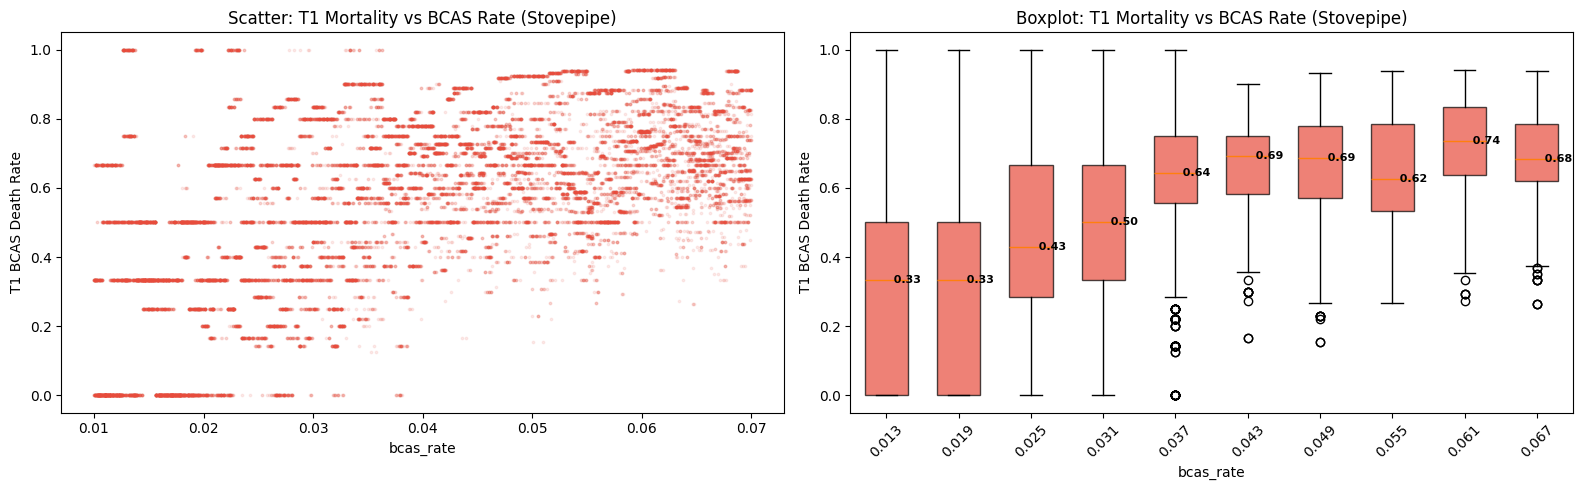

In [2]:
sub = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 0)]
print(f"Stovepipe: {len(sub)} runs")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scatter
axes[0].scatter(sub["bcas_rate"], sub["death_rate_T1_BCAS"], alpha=0.1, s=3, color="#e74c3c")
axes[0].set_xlabel("bcas_rate")
axes[0].set_ylabel("T1 BCAS Death Rate")
axes[0].set_title("Scatter: T1 Mortality vs BCAS Rate (Stovepipe)")

# Boxplot
bins = pd.qcut(sub["bcas_rate"], q=10, duplicates="drop")
groups = sub.groupby(bins, observed=True)
labels_bin = [f"{iv.mid:.3f}" for iv in groups.groups.keys()]
data = [g["death_rate_T1_BCAS"].values for _, g in groups]

bp = axes[1].boxplot(data, labels=labels_bin, patch_artist=True, widths=0.6)
for patch in bp["boxes"]:
    patch.set_facecolor("#e74c3c")
    patch.set_alpha(0.7)
for i, d in enumerate(data):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.2f}", va="center", fontsize=8, fontweight="bold")
axes[1].set_xlabel("bcas_rate")
axes[1].set_ylabel("T1 BCAS Death Rate")
axes[1].set_title("Boxplot: T1 Mortality vs BCAS Rate (Stovepipe)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [3]:
# Summary table — stovepipe only
bins = pd.qcut(sub["bcas_rate"], q=10, duplicates="drop")
summary = sub.groupby(bins, observed=True)["death_rate_T1_BCAS"].agg(["mean", "median", "std", "count"])
summary["nonzero_frac"] = sub.groupby(bins, observed=True)["death_rate_T1_BCAS"].apply(lambda x: (x > 0).mean())
print(summary.to_string(float_format="%.4f"))

                                mean  median    std  count  nonzero_frac
bcas_rate                                                               
(0.009000000000000001, 0.016] 0.3106  0.3333 0.2685   2460        0.6642
(0.016, 0.022]                0.3010  0.3333 0.2484   2460        0.6862
(0.022, 0.028]                0.4732  0.4286 0.2479   2454        0.9491
(0.028, 0.034]                0.5216  0.5000 0.2199   2460        0.9886
(0.034, 0.04]                 0.6206  0.6429 0.1783   2454        0.9943
(0.04, 0.046]                 0.6601  0.6923 0.1307   2460        1.0000
(0.046, 0.052]                0.6783  0.6875 0.1513   2460        1.0000
(0.052, 0.058]                0.6571  0.6250 0.1587   2454        1.0000
(0.058, 0.064]                0.7317  0.7368 0.1332   2460        1.0000
(0.064, 0.07]                 0.6930  0.6842 0.1215   2454        1.0000


C:\Users\User\AppData\Local\Temp\ipykernel_27628\2471034718.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data, labels=labels_bin, patch_artist=True, widths=0.6)
C:\Users\User\AppData\Local\Temp\ipykernel_27628\2471034718.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[1].boxplot(data2, labels=labels_bin, patch_artist=True, widths=0.6)


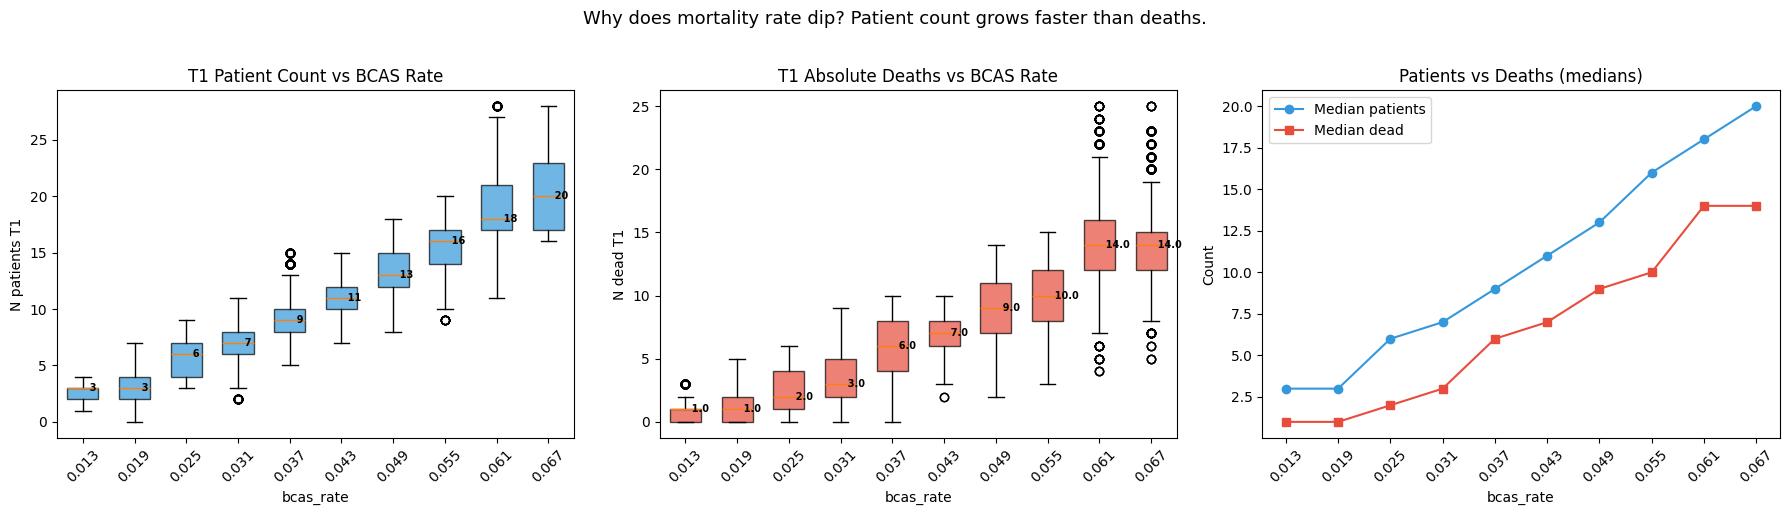

                       bcas_rate  med_patients  med_dead  med_rate
0  (0.009000000000000001, 0.016]          3.00      1.00      0.33
1                 (0.016, 0.022]          3.00      1.00      0.33
2                 (0.022, 0.028]          6.00      2.00      0.43
3                 (0.028, 0.034]          7.00      3.00      0.50
4                  (0.034, 0.04]          9.00      6.00      0.64
5                  (0.04, 0.046]         11.00      7.00      0.69
6                 (0.046, 0.052]         13.00      9.00      0.69
7                 (0.052, 0.058]         16.00     10.00      0.62
8                 (0.058, 0.064]         18.00     14.00      0.74
9                  (0.064, 0.07]         20.00     14.00      0.68


In [4]:
# Patient count and absolute deaths vs bcas
bins = pd.qcut(sub["bcas_rate"], q=10, duplicates="drop")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# N patients
groups = sub.groupby(bins, observed=True)
labels_bin = [f"{iv.mid:.3f}" for iv in groups.groups.keys()]
data = [g["n_patients_T1_BCAS"].values for _, g in groups]
bp = axes[0].boxplot(data, labels=labels_bin, patch_artist=True, widths=0.6)
for patch in bp["boxes"]:
    patch.set_facecolor("#3498db")
    patch.set_alpha(0.7)
for i, d in enumerate(data):
    med = np.median(d)
    axes[0].text(i + 1, med, f"  {med:.0f}", va="center", fontsize=7, fontweight="bold")
axes[0].set_xlabel("bcas_rate")
axes[0].set_ylabel("N patients T1")
axes[0].set_title("T1 Patient Count vs BCAS Rate")
axes[0].tick_params(axis="x", rotation=45)

# N dead (computed from rate × count)
sub_copy = sub.copy()
sub_copy["n_dead_T1"] = sub_copy["death_rate_T1_BCAS"] * sub_copy["n_patients_T1_BCAS"]
bins2 = pd.qcut(sub_copy["bcas_rate"], q=10, duplicates="drop")
groups2 = sub_copy.groupby(bins2, observed=True)
data2 = [g["n_dead_T1"].values for _, g in groups2]
bp2 = axes[1].boxplot(data2, labels=labels_bin, patch_artist=True, widths=0.6)
for patch in bp2["boxes"]:
    patch.set_facecolor("#e74c3c")
    patch.set_alpha(0.7)
for i, d in enumerate(data2):
    med = np.median(d)
    axes[1].text(i + 1, med, f"  {med:.1f}", va="center", fontsize=7, fontweight="bold")
axes[1].set_xlabel("bcas_rate")
axes[1].set_ylabel("N dead T1")
axes[1].set_title("T1 Absolute Deaths vs BCAS Rate")
axes[1].tick_params(axis="x", rotation=45)

# Summary: median patients, median dead, median rate
summary2 = sub_copy.groupby(bins2, observed=True).agg(
    med_patients=("n_patients_T1_BCAS", "median"),
    med_dead=("n_dead_T1", "median"),
    med_rate=("death_rate_T1_BCAS", "median"),
).reset_index()
axes[2].plot(range(len(summary2)), summary2["med_patients"], "o-", color="#3498db", label="Median patients")
axes[2].plot(range(len(summary2)), summary2["med_dead"], "s-", color="#e74c3c", label="Median dead")
axes[2].set_xticks(range(len(summary2)))
axes[2].set_xticklabels(labels_bin, rotation=45)
axes[2].set_xlabel("bcas_rate")
axes[2].set_ylabel("Count")
axes[2].set_title("Patients vs Deaths (medians)")
axes[2].legend()

plt.suptitle("Why does mortality rate dip? Patient count grows faster than deaths.", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print(summary2.to_string(float_format="%.2f"))